## Walkability Submetric
My submetric is the sidewalk-to-street ratio: the total length of sidewalks (and public steps) divided by the total length of street.

- A ratio of 1 means there is about as much sidewalk length as street length.
- A ratio of about 2 means that approximately every street has a sidewalk on both sides.
- A ratio near 0 means there are almost no sidewalks compared to streets.

Higher ratio = more walkable = better for local pedestrians

## Dataset

I used the [Sidewalk to Street "Walkability" Ratio](https://data.wprdc.org/dataset/sidewalk-to-street-walkability-ratio) (WPRDC, 2021) dataset for my analysis. The WPRDC already removed trails, crosswalks, highways, and alleys, so the ratio only counts sidewalks people actually walk on next to streets people can walk along.

To use the block codes in this dataset I also needed to access the city of pittsburgh [2010 Census Block Groups](https://data.wprdc.org/dataset/2010-census-block-groups).

In [1]:
%pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Loading the data

In [3]:
# GEOIDs are ID codes, not numbers, so read them as text (keeps any leading zeros)
walk = pd.read_csv("sidewalkstreetratioupload.csv", dtype={"GEOID": str})
hoods = pd.read_csv("2010NeighborhoodBlocks.csv", dtype=str, encoding="utf-8-sig")

print("Walkability rows:", len(walk))
print("Pittsburgh block group rows:", len(hoods))
walk.head()

Walkability rows: 2103
Pittsburgh block group rows: 361


,GEOID,NAMELSAD,SidewalkStepLFt,StreetLFt,Ratio
0,420030103001,Block Group 1,13392.83310,30315.86390,0.441776
1,420030103002,Block Group 2,31944.47597,20586.79493,1.551697
2,420030103003,Block Group 3,18655.20798,12122.70024,1.538866
3,420030103004,Block Group 4,14456.19616,11567.62831,1.249711
4,420030201001,Block Group 1,43952.94811,24426.52459,1.799394


In [4]:
# Geoids correlate to neighborhoods

hoods[["geoid10", "hood"]].head()

,geoid10,hood
0,420030405001,Central Oakland
1,420030404001,North Oakland
2,420030402002,West Oakland
3,420030305002,Crawford-Roberts
4,420030305001,Crawford-Roberts


## Clean and Merge

The walkability file includes some records with N/A or 0 street lengths. These are most likely errors, so we drop them. Some records also have N/A or 0 sidewalk lengths. This could be true in some locations, but I doubt there's a complete absence of sidewalks, so we drop those rows too. We also check for and remove duplicates.

The city block group key allows us to connect the GEOIDs from our walkability data to neighborhoods. We check it for duplicates and N/As and remove them. We then keep only the geoid and hood columns and rename them to match the walkability dataset.

After both datasets are clean, we merge the two on the GEOID column so we have one table with each walkability ratio right next to its neighborhood.

In [5]:
# Walkability Dataset Cleaning
print("Rows before cleaning:", len(walk))
print()

print("Missing (N/A) values:")
print(" Street length:  ", walk["StreetLFt"].isna().sum())
print(" Sidewalk length:", walk["SidewalkStepLFt"].isna().sum())
print()

print("Zero values:")
print(" Street length:  ", (walk["StreetLFt"] == 0).sum())
print(" Sidewalk length:", (walk["SidewalkStepLFt"] == 0).sum())
print()

print("Duplicate GEOIDs in walkability:", walk["GEOID"].duplicated().sum())
print()

Rows before cleaning: 2103

Missing (N/A) values:
 Street length:   1003
 Sidewalk length: 1023

Zero values:
 Street length:   0
 Sidewalk length: 0

Duplicate GEOIDs in walkability: 0



In [6]:
# Drop rows with an N/A in either column 
walk = walk.dropna(subset=["StreetLFt", "SidewalkStepLFt"])
# Drop rows with a 0 in either column
walk = walk[(walk["StreetLFt"] > 0) & (walk["SidewalkStepLFt"] > 0)]

walk = walk.drop_duplicates(subset="GEOID")

print("Rows after cleaning:", len(walk))

Rows after cleaning: 1080


In [7]:
# Neighborhood GEOID Dataset Cleaning
print("Rows before cleaning:", len(hoods))
print()

print("Duplicate GEOIDs in city file:", hoods["geoid10"].duplicated().sum())
print("N/As in city file:")
print(hoods[["geoid10", "hood"]].isna().sum())

Rows before cleaning: 361

Duplicate GEOIDs in city file: 2
N/As in city file:
geoid10    0
hood       0
dtype: int64


In [8]:
hoods = hoods.dropna(subset=["geoid10", "hood"])
hoods = hoods.drop_duplicates(subset="geoid10")

print("Rows after cleaning:", len(hoods))
print()

id_to_hood = (
    hoods[["geoid10", "hood"]]
    .rename(columns={"geoid10": "GEOID", "hood": "Neighborhood"})
)

print("Unique block groups:", len(id_to_hood))
print("Unique neighborhoods:", id_to_hood["Neighborhood"].nunique())
id_to_hood.head()

Rows after cleaning: 359

Unique block groups: 359
Unique neighborhoods: 91


,GEOID,Neighborhood
0,420030405001,Central Oakland
1,420030404001,North Oakland
2,420030402002,West Oakland
3,420030305002,Crawford-Roberts
4,420030305001,Crawford-Roberts


In [9]:
# Merge: this keeps only records that have locations in both datasets
pgh = walk.merge(id_to_hood, on="GEOID", how="inner")
print("Pittsburgh block groups with walkability data:", len(pgh))
print("Neighborhoods with walkability data:", pgh["Neighborhood"].nunique())
pgh.head()

Pittsburgh block groups with walkability data: 359
Neighborhoods with walkability data: 91


,GEOID,NAMELSAD,SidewalkStepLFt,StreetLFt,Ratio,Neighborhood
0,420030103001,Block Group 1,13392.83310,30315.86390,0.441776,Bluff
1,420030103002,Block Group 2,31944.47597,20586.79493,1.551697,Bluff
2,420030103003,Block Group 3,18655.20798,12122.70024,1.538866,Bluff
3,420030103004,Block Group 4,14456.19616,11567.62831,1.249711,Bluff
4,420030201001,Block Group 1,43952.94811,24426.52459,1.799394,Central Business District


## Calculating walkability per neighborhood
Instead of averaging the block group ratios, we add up all the sidewalk and all the street in each neighborhood and divide to recalculate the ratio. That way, one tiny block group with an extreme ratio can't skew a whole neighborhood, and bigger areas count proportionally more.

In [10]:
by_hood = pgh.groupby("Neighborhood").agg(
    sidewalk_ft=("SidewalkStepLFt", "sum"),
    street_ft=("StreetLFt", "sum"),
    block_groups=("GEOID", "count"),
)
by_hood["walk_ratio"] = (by_hood["sidewalk_ft"] / by_hood["street_ft"]).round(3)
by_hood = by_hood.sort_values("walk_ratio", ascending=False)

by_hood.head(10)

,sidewalk_ft,street_ft,block_groups,walk_ratio
Neighborhood,,,,
Bedford Dwellings,34060.434850,5125.794855,1,6.645
Allegheny Center,59326.329020,18381.709480,1,3.227
Northview Heights,58729.595540,21650.722550,1,2.713
Terrace Village,65042.566700,24188.701186,3,2.689
North Oakland,110641.508274,48545.339042,6,2.279
Central Lawrenceville,104327.773427,53424.433119,6,1.953
Larimer,96323.479200,49445.310614,4,1.948
Point Breeze North,51109.056360,26430.766961,3,1.934
North Shore,51316.991000,26679.973380,2,1.923


In [11]:
# The least walkable neighborhoods, for comparison
by_hood.tail(10)

,sidewalk_ft,street_ft,block_groups,walk_ratio
Neighborhood,,,,
West End,20266.483830,30134.82102,1,0.673
Westwood,38577.688570,58854.38551,2,0.655
Bon Air,14717.636770,24818.36751,1,0.593
Ridgemont,6369.255036,12630.27445,1,0.504
Banksville,34934.687055,93150.63236,4,0.375
Hays,8109.186525,28336.47574,1,0.286
Chartiers City,3393.271454,11907.04963,1,0.285
Summer Hill,8352.955184,32732.39614,1,0.255
Lincoln Place,20389.007392,96125.50497,5,0.212


## Visualizing the results

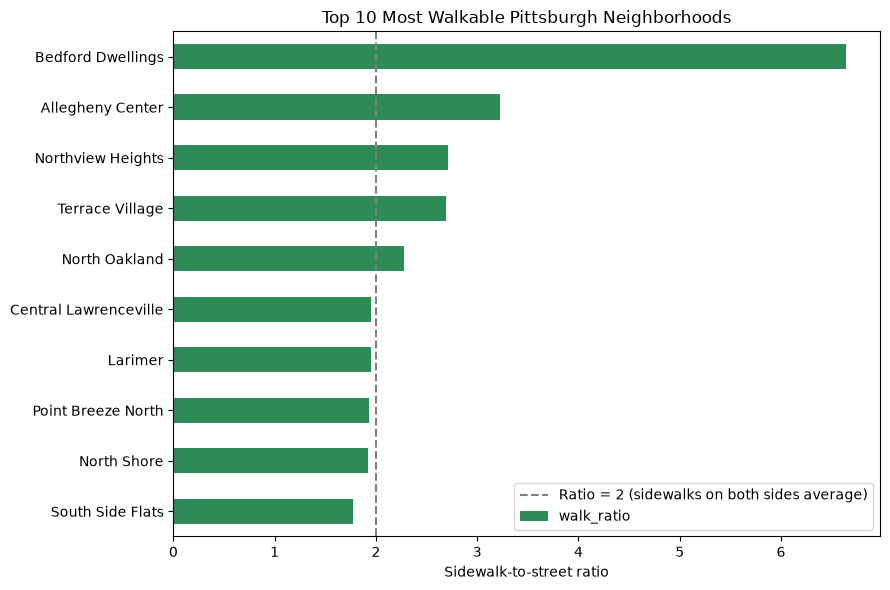

In [12]:
top10 = by_hood.head(10)

ax = top10["walk_ratio"].plot(kind="barh", figsize=(9, 6), color="seagreen")
ax.invert_yaxis()
ax.axvline(2, color="gray", linestyle="--", label="Ratio = 2 (sidewalks on both sides average)")
ax.set_xlabel("Sidewalk-to-street ratio")
ax.set_ylabel("")
ax.set_title("Top 10 Most Walkable Pittsburgh Neighborhoods")
ax.legend()
plt.tight_layout()
plt.show()

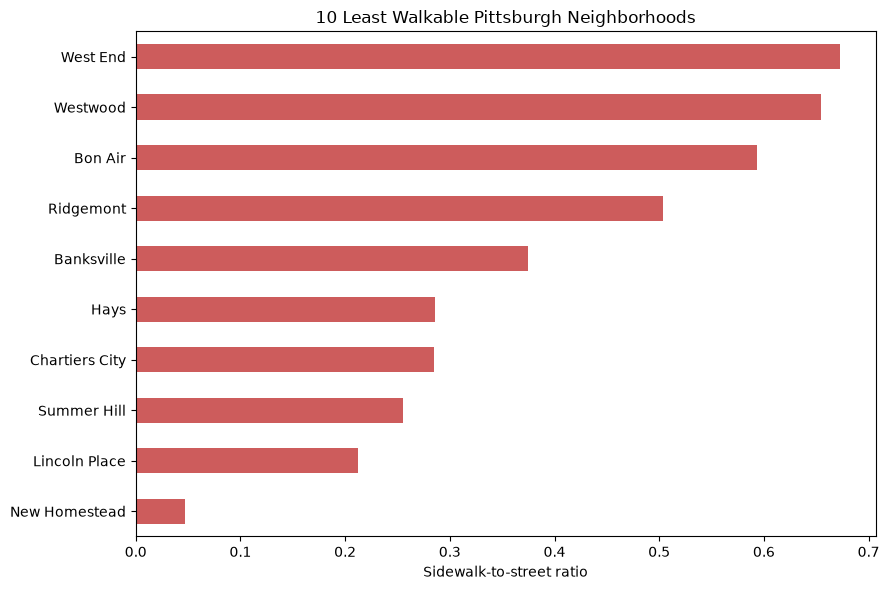

In [13]:
bottom10 = by_hood.tail(10)

ax = bottom10["walk_ratio"].plot(kind="barh", figsize=(9, 6), color="indianred")
ax.invert_yaxis()
ax.set_xlabel("Sidewalk-to-street ratio")
ax.set_ylabel("")
ax.set_title("10 Least Walkable Pittsburgh Neighborhoods")
plt.tight_layout()
plt.show()

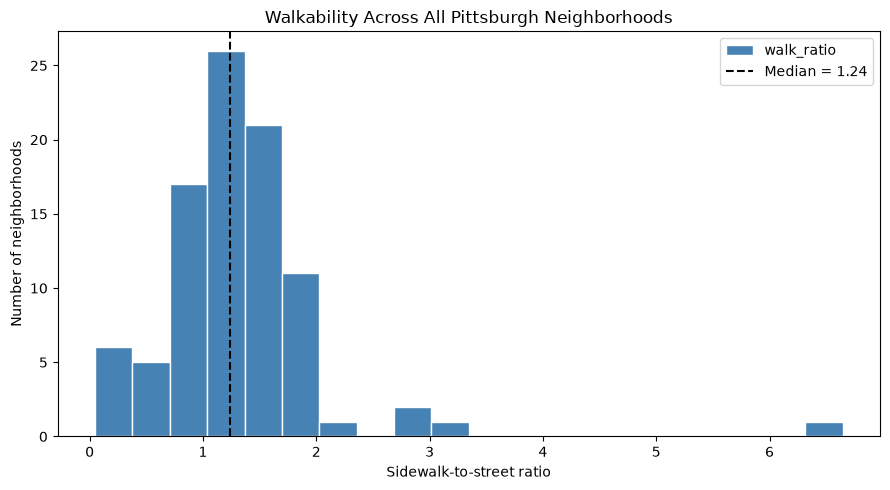

In [14]:
# How walkability is spread out across all neighborhoods
ax = by_hood["walk_ratio"].plot(kind="hist", bins=20, figsize=(9, 5), color="steelblue", edgecolor="white")
ax.axvline(by_hood["walk_ratio"].median(), color="black", linestyle="--",
           label=f"Median = {by_hood['walk_ratio'].median():.2f}")
ax.set_xlabel("Sidewalk-to-street ratio")
ax.set_ylabel("Number of neighborhoods")
ax.set_title("Walkability Across All Pittsburgh Neighborhoods")
ax.legend()
plt.tight_layout()
plt.show()

## My submetric score
To make combining with my teammates' submetrics easy, I convert the ratio to a percentile score from 0 to 100. The most walkable neighborhood gets 100, meaning it's better than every other neighborhood. A score of ~50 means the neighborhood is more walkable than half of the other neighborhoods and less walkable than the other half. I used percentiles instead of dividing by the highest ratio because one of the neighborhoods is such an outlier that it would have pushed every other neighborhood's score down in a manner unrepresentative of the actual walkability in my opinion.

In [15]:
by_hood["walk_score"] = (by_hood["walk_ratio"].rank(pct=True) * 100).round(1)

# Save the scores so they can be merged into the group notebook
by_hood[["walk_ratio", "walk_score"]].to_csv("colin_walkability_scores.csv")

best = by_hood.index[0]
print("Most walkable neighborhood:", best)
by_hood.loc[best]

Most walkable neighborhood: Bedford Dwellings


sidewalk_ft     34060.434850
street_ft        5125.794855
block_groups        1.000000
walk_ratio          6.645000
walk_score        100.000000
Name: Bedford Dwellings, dtype: float64

## Conclusion

According to my submetric, the most walkable neighborhood in Pittsburgh is Bedford Dwellings, with a sidewalk-to-street ratio of 6.645, meaning it has about 6.645 feet of sidewalk for every foot of street. This makes sense as the neighborhood is essentially walkways (counting as sidewalks) through a public housing complex with a small amount of roads on the edge of the nieghborhood. 

Some things I noticed:
- The majority of the most highest scoring neighborhoods are planned developments like Bedford Dwellings based around public housing complexes with lots of paths in between them and roads that outline the area. This ends up pushing their ratios extremely high. Though, this does not take away from the fact that these are correctly idenitified as walkable neighborhoods.
- The neighborhoods below the planned development ones are Central Lawrenceville, North Oakland, South Side Flats, Point Breeze North, and North Shore all with a ratio of ~2. These all are older neighborhoods that were built before most people had cars, built near the rivers or on flat land when walking was the main method of local transport. These could be argued as the real winners of my metric as they are more walkable in the traditional sense and not public planned developments.
- The lowest ranking neighborhoods are alot of the times found on the hilly edges of Pittsburgh. West End, Westwood, Ridgemont, Banksville, Chartiers City, and Lincoln Place are mostly on the west and south sides, and New Homestead and Hays are at the far southeast. The nieghborhoods are built like suburbs with winding roads and a lack of sidewalks, on top of the fact that the hillyness contributes to an inability to comfortably walk.

Limitations: The data is from 2021. A sidewalk existing doesn't mean it's in good condition, also Pittsburgh's hills and many steps make some "walkable" areas tough to actually walk. This metrics also doesnt captures which sidewalks are the safest to walk on, some may be more protected from vehicles than others or in more vulnerable areas alongside highways/busy roads. There is always the chance of errors in how the sidewalks and streets were mapped, which could affect some neighborhoods more than others.